# Step 1: Library Imports

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-Learn modules for preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier # For Feature Selection

# Models for Classification
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

# Display settings
import warnings
warnings.filterwarnings('ignore')
%matplotlib inline
pd.set_option('display.max_columns', None)

# Step 2: Loading dataset

In [ ]:
df = pd.read_csv('marketing_campaign.csv', sep='\t')

In [ ]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,88,546,172,88,88,3,8,10,4,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,1,6,2,1,6,2,1,1,2,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,49,127,111,21,42,1,8,2,10,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,4,20,10,3,5,2,2,0,4,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,43,118,46,27,15,5,5,3,6,5,0,0,0,0,0,0,3,11,0


In [ ]:
print(df['Education'].unique())
print(df['Marital_Status'].unique())
print(df['Z_CostContact'].unique())
print(df['Z_Revenue'].unique())


['Graduation' 'PhD' 'Master' 'Basic' '2n Cycle']
['Single' 'Together' 'Married' 'Divorced' 'Widow' 'Alone' 'Absurd' 'YOLO']
[3]
[11]


In [ ]:
df.drop(columns=['Z_Revenue', 'Z_CostContact','ID'], inplace=True)

In [ ]:
df.head()

,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Response
0,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,88,546,172,88,88,3,8,10,4,7,0,0,0,0,0,0,1
1,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,1,6,2,1,6,2,1,1,2,5,0,0,0,0,0,0,0
2,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,49,127,111,21,42,1,8,2,10,4,0,0,0,0,0,0,0
3,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,4,20,10,3,5,2,2,0,4,6,0,0,0,0,0,0,0
4,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,43,118,46,27,15,5,5,3,6,5,0,0,0,0,0,0,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 26 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Year_Birth           2240 non-null   int64  
 1   Education            2240 non-null   object 
 2   Marital_Status       2240 non-null   object 
 3   Income               2216 non-null   float64
 4   Kidhome              2240 non-null   int64  
 5   Teenhome             2240 non-null   int64  
 6   Dt_Customer          2240 non-null   object 
 7   Recency              2240 non-null   int64  
 8   MntWines             2240 non-null   int64  
 9   MntFruits            2240 non-null   int64  
 10  MntMeatProducts      2240 non-null   int64  
 11  MntFishProducts      2240 non-null   int64  
 12  MntSweetProducts     2240 non-null   int64  
 13  MntGoldProds         2240 non-null   int64  
 14  NumDealsPurchases    2240 non-null   int64  
 15  NumWebPurchases      2240 non-null   i

In [ ]:
df.describe()

,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Response
count,2240.000000,2216.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000
mean,1968.805804,52247.251354,0.444196,0.506250,49.109375,303.935714,26.302232,166.950000,37.525446,27.062946,44.021875,2.325000,4.084821,2.662054,5.790179,5.316518,0.072768,0.074554,0.072768,0.064286,0.013393,0.009375,0.149107
std,11.984069,25173.076661,0.538398,0.544538,28.962453,336.597393,39.773434,225.715373,54.628979,41.280498,52.167439,1.932238,2.778714,2.923101,3.250958,2.426645,0.259813,0.262728,0.259813,0.245316,0.114976,0.096391,0.356274
min,1893.000000,1730.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1959.000000,35303.000000,0.000000,0.000000,24.000000,23.750000,1.000000,16.000000,3.000000,1.000000,9.000000,1.000000,2.000000,0.000000,3.000000,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,1970.000000,51381.500000,0.000000,0.000000,49.000000,173.500000,8.000000,67.000000,12.000000,8.000000,24.000000,2.000000,4.000000,2.000000,5.000000,6.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,1977.000000,68522.000000,1.000000,1.000000,74.000000,504.250000,33.000000,232.000000,50.000000,33.000000,56.000000,3.000000,6.000000,4.000000,8.000000,7.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,1996.000000,666666.000000,2.000000,2.000000,99.000000,1493.000000,199.000000,1725.000000,259.000000,263.000000,362.000000,15.000000,27.000000,28.000000,13.000000,20.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [ ]:
df.describe(exclude='number')

,Education,Marital_Status,Dt_Customer
count,2240,2240,2240
unique,5,8,663
top,Graduation,Married,31-08-2012
freq,1127,864,12


# Step 3: Data cleaning

In [ ]:
# 1. Remove duplicate rows
initial_shape = df.shape
df = df.drop_duplicates()
print(f"Dropped {initial_shape[0] - df.shape[0]} duplicate rows.")

Dropped 0 duplicate rows.


In [ ]:
# 2. Identify missing values
print("\n--- Missing Values Count ---")
print(df.isnull().sum())


--- Missing Values Count ---
Year_Birth             0
Education              0
Marital_Status         0
Income                 0
Kidhome                0
Teenhome               0
Dt_Customer            0
Recency                0
MntWines               0
MntFruits              0
MntMeatProducts        0
MntFishProducts        0
MntSweetProducts       0
MntGoldProds           0
NumDealsPurchases      0
NumWebPurchases        0
NumCatalogPurchases    0
NumStorePurchases      0
NumWebVisitsMonth      0
AcceptedCmp3           0
AcceptedCmp4           0
AcceptedCmp5           0
AcceptedCmp1           0
AcceptedCmp2           0
Complain               0
Response               0
dtype: int64


In [ ]:
df['Income'] = df['Income'].fillna(df['Income'].mean())

In [ ]:
df.head()

,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Response
0,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,88,546,172,88,88,3,8,10,4,7,0,0,0,0,0,0,1
1,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,1,6,2,1,6,2,1,1,2,5,0,0,0,0,0,0,0
2,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,49,127,111,21,42,1,8,2,10,4,0,0,0,0,0,0,0
3,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,4,20,10,3,5,2,2,0,4,6,0,0,0,0,0,0,0
4,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,43,118,46,27,15,5,5,3,6,5,0,0,0,0,0,0,0


# Step 4: Outliers detection & treatment

In [ ]:
def get_outlier_limits(dataframe, column, method='iqr'):
    """Calculates upper and lower limits based on the selected method."""
    if method == 'iqr':
        Q1 = dataframe[column].quantile(0.25)
        Q3 = dataframe[column].quantile(0.75)
        IQR = Q3 - Q1
        lower_limit = Q1 - 1.5 * IQR
        upper_limit = Q3 + 1.5 * IQR
    elif method == 'z-score':
        mean = dataframe[column].mean()
        std = dataframe[column].std()
        lower_limit = mean - 3 * std # 3 Standard Deviations
        upper_limit = mean + 3 * std
    elif method == 'percentile':
        lower_limit = dataframe[column].quantile(0.01) # 1st Percentile
        upper_limit = dataframe[column].quantile(0.99) # 99th Percentile
    else:
        raise ValueError("Method must be 'iqr', 'z-score', or 'percentile'")
    return lower_limit, upper_limit

def treat_outliers(dataframe, column, method='iqr', treatment='cap'):
    """Applies capping or trimming to the specified column."""
    df_treated = dataframe.copy()
    lower_limit, upper_limit = get_outlier_limits(df_treated, column, method)

    if treatment == 'cap':
        df_treated[column] = np.clip(df_treated[column], lower_limit, upper_limit)
    elif treatment == 'trim':
        df_treated = df_treated[(df_treated[column] >= lower_limit) & (df_treated[column] <= upper_limit)]
    else:
        raise ValueError("Treatment must be 'cap' or 'trim'")

    return df_treated

num_cols = df.select_dtypes(include=['float64', 'int64']).columns
sample_col = 'HeartDisease' if 'HeartDisease' in num_cols else num_cols[0]


In [ ]:
# ---------------------------------------------------------
# COMPARISON BLOCK: Testing all methods on a single column
# ---------------------------------------------------------
methods = ['iqr', 'z-score', 'percentile']
treatments = ['cap', 'trim']

print(f"--- Comparing Outlier Treatments for column: '{sample_col}' ---")
print(f"Original shape: {df.shape} | Original variance: {df[sample_col].var():.2f}\n")

for method in methods:
    for treatment in treatments:
        test_df = treat_outliers(df, sample_col, method=method, treatment=treatment)
        print(f"Method: {method.upper():<10} | Treatment: {treatment.upper():<4} | New Shape: {test_df.shape} | New Variance: {test_df[sample_col].var():.2f}")

--- Comparing Outlier Treatments for column: 'Year_Birth' ---
Original shape: (2058, 26) | Original variance: 143.37

Method: IQR        | Treatment: CAP  | New Shape: (2058, 26) | New Variance: 137.89
Method: IQR        | Treatment: TRIM | New Shape: (2055, 26) | New Variance: 136.10
Method: Z-SCORE    | Treatment: CAP  | New Shape: (2058, 26) | New Variance: 137.79
Method: Z-SCORE    | Treatment: TRIM | New Shape: (2055, 26) | New Variance: 136.10
Method: PERCENTILE | Treatment: CAP  | New Shape: (2058, 26) | New Variance: 135.33
Method: PERCENTILE | Treatment: TRIM | New Shape: (2027, 26) | New Variance: 128.91


In [ ]:
cols_for_outlier_summary = [col for col in num_cols if col != 'Student Age']

summary_rows = []

for col in cols_for_outlier_summary:
    for method in methods:
        lower_limit, upper_limit = get_outlier_limits(df, col, method=method)

        outliers_mask = (df[col] < lower_limit) | (df[col] > upper_limit)
        n_outliers = outliers_mask.sum()

        if n_outliers > 0:
            outlier_min = df.loc[outliers_mask, col].min()
            outlier_max = df.loc[outliers_mask, col].max()
            outlier_range = f"[{outlier_min:.2f}, {outlier_max:.2f}]"
        else:
            outlier_range = "No outliers"

        # Simulate actual capping to get the REAL resulting range (not just the raw limits)
        capped_col = np.clip(df[col], lower_limit, upper_limit)
        actual_capped_min = capped_col.min()
        actual_capped_max = capped_col.max()
        capped_range = f"[{actual_capped_min:.2f}, {actual_capped_max:.2f}]"

        summary_rows.append({
            "Column": col,
            "Method": method.upper(),
            "Outliers Detected": n_outliers,
            "Original Outlier Range": outlier_range,
            "Range After Capping (Actual)": capped_range
        })

outlier_summary_df = pd.DataFrame(summary_rows)

pd.set_option('display.max_rows', None)
display(outlier_summary_df)

,Column,Method,Outliers Detected,Original Outlier Range,Range After Capping (Actual)
0,Year_Birth,IQR,3,"[1893.00, 1900.00]","[1932.00, 1996.00]"
1,Year_Birth,Z-SCORE,3,"[1893.00, 1900.00]","[1932.87, 1996.00]"
2,Year_Birth,PERCENTILE,31,"[1893.00, 1996.00]","[1945.00, 1992.00]"
3,Income,IQR,8,"[153924.00, 666666.00]","[1730.00, 117053.62]"
4,Income,Z-SCORE,8,"[153924.00, 666666.00]","[1730.00, 128490.60]"
5,Income,PERCENTILE,32,"[1730.00, 666666.00]","[7500.00, 94545.10]"
6,Kidhome,IQR,0,No outliers,"[0.00, 2.00]"
7,Kidhome,Z-SCORE,0,No outliers,"[0.00, 2.00]"
8,Kidhome,PERCENTILE,0,No outliers,"[0.00, 2.00]"
9,Teenhome,IQR,0,No outliers,"[0.00, 2.00]"


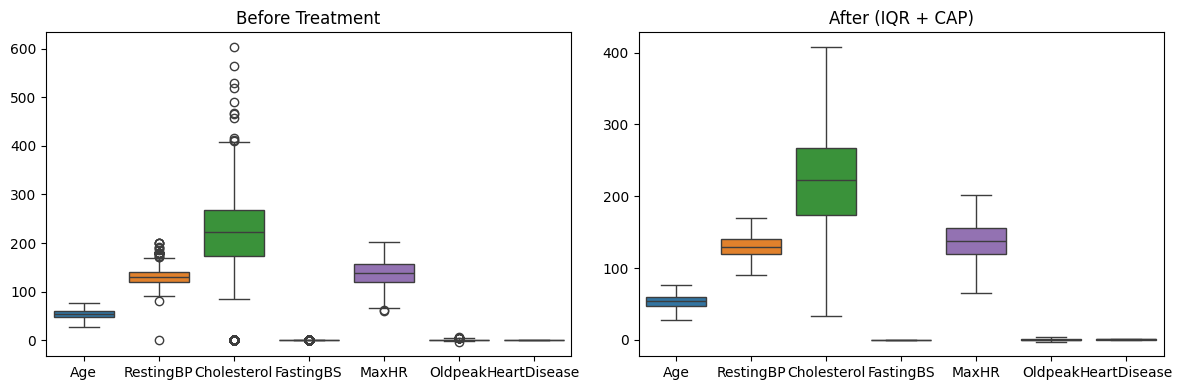


Applied IQR with CAPping to all numerical columns. Final shape: (918, 12)


In [ ]:
# ---------------------------------------------------------
# APPLYING CHOSEN STRATEGY TO ALL NUMERICAL COLUMNS
# ---------------------------------------------------------
# Set your preferred method based on the comparison above:
chosen_method = 'iqr'      # options: 'iqr', 'z-score', 'percentile'
chosen_treatment = 'cap'   # options: 'cap', 'trim'

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
sns.boxplot(data=df[num_cols])
plt.title("Before Treatment")

for col in num_cols:
    df = treat_outliers(df, col, method=chosen_method, treatment=chosen_treatment)

plt.subplot(1, 2, 2)
sns.boxplot(data=df[num_cols])
plt.title(f"After ({chosen_method.upper()} + {chosen_treatment.upper()})")
plt.tight_layout()
plt.show()

print(f"\nApplied {chosen_method.upper()} with {chosen_treatment.upper()}ping to all numerical columns. Final shape: {df.shape}")

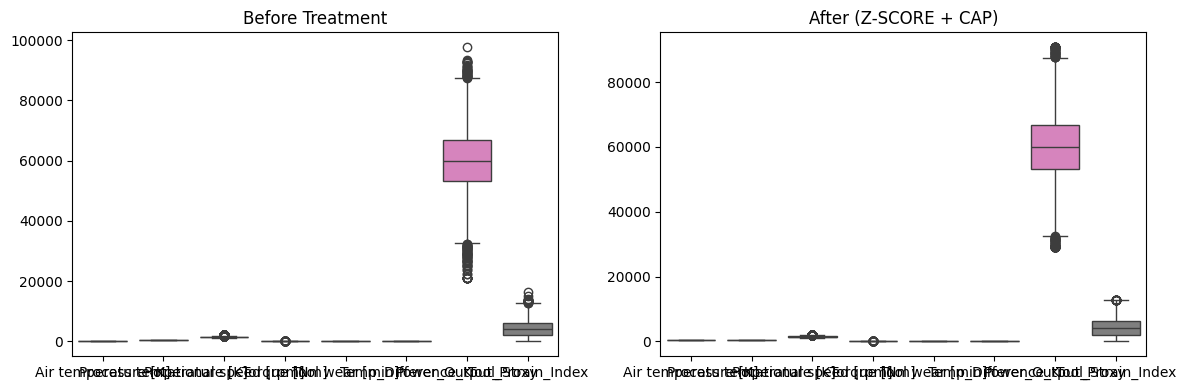


Applied Z-SCORE with CAPping to all numerical columns. Final shape: (10000, 10)


In [ ]:
# ---------------------------------------------------------
# APPLYING CHOSEN STRATEGY TO ALL NUMERICAL COLUMNS
# ---------------------------------------------------------
# Set your preferred method based on the comparison above:
chosen_method = 'z-score'      # options: 'iqr', 'z-score', 'percentile'
chosen_treatment = 'cap'   # options: 'cap', 'trim'

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
sns.boxplot(data=df[num_cols])
plt.title("Before Treatment")

for col in num_cols:
    df = treat_outliers(df, col, method=chosen_method, treatment=chosen_treatment)

plt.subplot(1, 2, 2)
sns.boxplot(data=df[num_cols])
plt.title(f"After ({chosen_method.upper()} + {chosen_treatment.upper()})")
plt.tight_layout()
plt.show()

print(f"\nApplied {chosen_method.upper()} with {chosen_treatment.upper()}ping to all numerical columns. Final shape: {df.shape}")

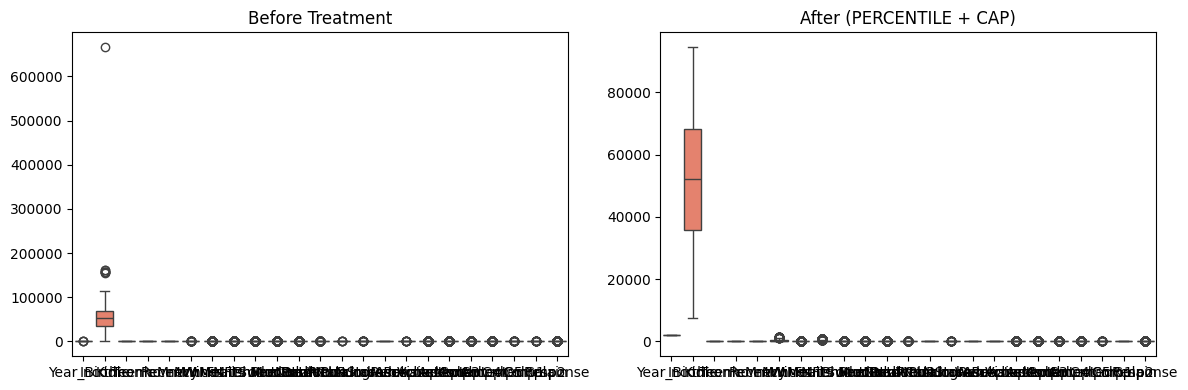


Applied PERCENTILE with CAPping to all numerical columns. Final shape: (2058, 26)


In [ ]:
# ---------------------------------------------------------
# APPLYING CHOSEN STRATEGY TO ALL NUMERICAL COLUMNS
# ---------------------------------------------------------
# Set your preferred method based on the comparison above:
chosen_method = 'percentile'      # options: 'iqr', 'z-score', 'percentile'
chosen_treatment = 'cap'   # options: 'cap', 'trim'

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
sns.boxplot(data=df[num_cols])
plt.title("Before Treatment")

for col in num_cols:
    df = treat_outliers(df, col, method=chosen_method, treatment=chosen_treatment)

plt.subplot(1, 2, 2)
sns.boxplot(data=df[num_cols])
plt.title(f"After ({chosen_method.upper()} + {chosen_treatment.upper()})")
plt.tight_layout()
plt.show()

print(f"\nApplied {chosen_method.upper()} with {chosen_treatment.upper()}ping to all numerical columns. Final shape: {df.shape}")

# Step 5: Feature Engineering

In [ ]:
df['Age'] = 2021 - df['Year_Birth']
df.drop('Year_Birth', axis=1, inplace=True)

In [ ]:
df['Dt_Customer'] = pd.to_datetime(df['Dt_Customer'], dayfirst=True)  # adjust format if needed
reference_date = pd.to_datetime('2021-01-01')  # or df['Dt_Customer'].max()
df['Customer_Tenure'] = (reference_date - df['Dt_Customer']).dt.days
df.drop('Dt_Customer', axis=1, inplace=True)

In [ ]:
df['Total_Spending'] = (df['MntWines'] + df['MntFruits'] + df['MntMeatProducts'] +
                         df['MntFishProducts'] + df['MntSweetProducts'] + df['MntGoldProds'])

In [ ]:
df['Total_Purchases'] = (df['NumWebPurchases'] + df['NumCatalogPurchases'] +
                          df['NumStorePurchases'] + df['NumDealsPurchases'])

In [ ]:
campaign_cols = ['AcceptedCmp1', 'AcceptedCmp2', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'Response']
df['Campaigns_Count'] = df[campaign_cols].sum(axis=1)
df['Avg_Campaigns_Accepted'] = df['Campaigns_Count'] / 6

In [ ]:
df.drop('Campaigns_Count', axis=1, inplace=True)

In [ ]:
df.drop(['AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1', 'AcceptedCmp2', 'Response'],
        axis=1, inplace=True)

In [ ]:
df.head()

,Education,Marital_Status,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Response,Age,Customer_Tenure,Total_Spending,Total_Purchases,Avg_Campaigns_Accepted
0,Graduation,Single,58138.0,0,0,58,635,88,546.0,172.0,88.0,88.0,3,8,10,4,7,0,0,0,0,0,0,1,64,3041,1617.0,25,0.166667
1,Graduation,Single,46344.0,1,1,38,11,1,6.0,2.0,1.0,6.0,2,1,1,2,5,0,0,0,0,0,0,0,67,2491,27.0,6,0.000000
2,Graduation,Together,71613.0,0,0,26,426,49,127.0,111.0,21.0,42.0,1,8,2,10,4,0,0,0,0,0,0,0,56,2690,776.0,21,0.000000
3,Graduation,Together,26646.0,1,0,26,11,4,20.0,10.0,3.0,5.0,2,2,0,4,6,0,0,0,0,0,0,0,37,2517,53.0,8,0.000000
4,PhD,Married,58293.0,1,0,94,173,43,118.0,46.0,27.0,15.0,5,5,3,6,5,0,0,0,0,0,0,0,40,2539,422.0,19,0.000000


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2058 entries, 0 to 2239
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Income                   2058 non-null   float64
 1   Kidhome                  2058 non-null   int64  
 2   Teenhome                 2058 non-null   int64  
 3   Recency                  2058 non-null   int64  
 4   MntWines                 2058 non-null   int64  
 5   MntFruits                2058 non-null   int64  
 6   MntMeatProducts          2058 non-null   float64
 7   MntFishProducts          2058 non-null   float64
 8   MntSweetProducts         2058 non-null   float64
 9   MntGoldProds             2058 non-null   float64
 10  NumDealsPurchases        2058 non-null   int64  
 11  NumWebPurchases          2058 non-null   int64  
 12  NumCatalogPurchases      2058 non-null   int64  
 13  NumStorePurchases        2058 non-null   int64  
 14  NumWebVisitsMonth        2058

# Step 6: Data Encoding

In [ ]:
print(df['Education'].value_counts())
print(df['Marital_Status'].value_counts())

Education
Graduation    1030
PhD            450
Master         341
2n Cycle       188
Basic           49
Name: count, dtype: int64
Marital_Status
Married     795
Together    521
Single      455
Divorced    216
Widow        71
Name: count, dtype: int64


In [ ]:
df['Marital_Status'] = df['Marital_Status'].replace({
    'Alone': 'Single',
    'Absurd': 'Single',
    'YOLO': 'Single'
})

In [ ]:
df = pd.get_dummies(df, columns=['Education', 'Marital_Status'], drop_first=False)

In [ ]:
dummy_cols = [col for col in df.columns if col.startswith('Education_') or col.startswith('Marital_Status_')]
df[dummy_cols] = df[dummy_cols].astype(int)

In [ ]:
df.head()

,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Response,Age,Customer_Tenure,Total_Spending,Total_Purchases,Avg_Campaigns_Accepted,Education_2n Cycle,Education_Basic,Education_Graduation,Education_Master,Education_PhD,Marital_Status_Divorced,Marital_Status_Married,Marital_Status_Single,Marital_Status_Together,Marital_Status_Widow
0,58138.0,0,0,58,635,88,546.0,172.0,88.0,88.0,3,8,10,4,7,0,0,0,0,0,0,1,64,3041,1617.0,25,0.166667,0,0,1,0,0,0,0,1,0,0
1,46344.0,1,1,38,11,1,6.0,2.0,1.0,6.0,2,1,1,2,5,0,0,0,0,0,0,0,67,2491,27.0,6,0.000000,0,0,1,0,0,0,0,1,0,0
2,71613.0,0,0,26,426,49,127.0,111.0,21.0,42.0,1,8,2,10,4,0,0,0,0,0,0,0,56,2690,776.0,21,0.000000,0,0,1,0,0,0,0,0,1,0
3,26646.0,1,0,26,11,4,20.0,10.0,3.0,5.0,2,2,0,4,6,0,0,0,0,0,0,0,37,2517,53.0,8,0.000000,0,0,1,0,0,0,0,0,1,0
4,58293.0,1,0,94,173,43,118.0,46.0,27.0,15.0,5,5,3,6,5,0,0,0,0,0,0,0,40,2539,422.0,19,0.000000,0,0,0,0,1,0,1,0,0,0


# Feature Scaling and preparing for K model

In [ ]:
from sklearn.preprocessing import StandardScaler

X = df.copy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Convert back to a DataFrame with column names preserved (useful for inspection later)
X_scaled = pd.DataFrame(X_scaled, columns=X.columns, index=X.index)

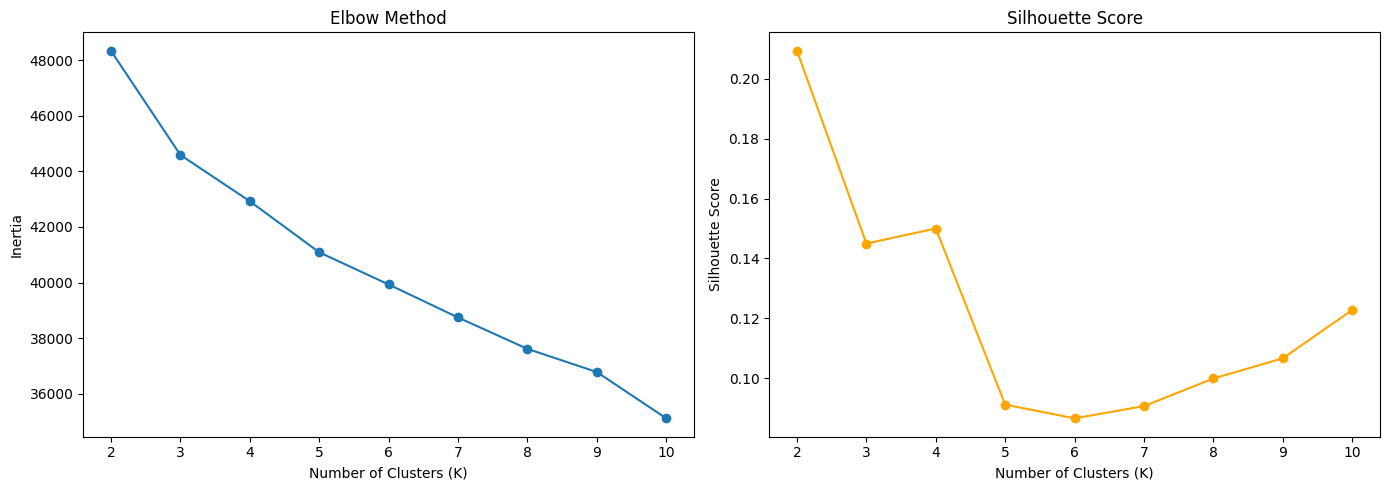

K=2: Inertia=48336.7, Silhouette=0.2094
K=3: Inertia=44589.4, Silhouette=0.1450
K=4: Inertia=42924.8, Silhouette=0.1500
K=5: Inertia=41087.0, Silhouette=0.0911
K=6: Inertia=39930.7, Silhouette=0.0865
K=7: Inertia=38742.4, Silhouette=0.0906
K=8: Inertia=37613.5, Silhouette=0.0998
K=9: Inertia=36780.0, Silhouette=0.1066
K=10: Inertia=35114.7, Silhouette=0.1227


In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

inertia = []
silhouette_scores = []
K_range = range(2, 11)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertia.append(km.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, labels))

# Plot both side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(K_range, inertia, marker='o')
axes[0].set_xlabel('Number of Clusters (K)')
axes[0].set_ylabel('Inertia')
axes[0].set_title('Elbow Method')

axes[1].plot(K_range, silhouette_scores, marker='o', color='orange')
axes[1].set_xlabel('Number of Clusters (K)')
axes[1].set_ylabel('Silhouette Score')
axes[1].set_title('Silhouette Score')

plt.tight_layout()
plt.show()

# Print exact values too
for k, i, s in zip(K_range, inertia, silhouette_scores):
    print(f"K={k}: Inertia={i:.1f}, Silhouette={s:.4f}")

In [ ]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(X_scaled)

df['Cluster'].value_counts()

,count
Cluster,
1,926
3,557
2,504
0,71


In [ ]:
df['Cluster'].value_counts().sort_index()

,count
Cluster,
0,71
1,926
2,504
3,557


In [ ]:
profile_cols = ['Income', 'Age', 'Total_Spending', 'Total_Purchases',
                 'Customer_Tenure', 'Avg_Campaigns_Accepted', 'Kidhome', 'Teenhome',
                 'NumWebVisitsMonth', 'NumDealsPurchases', 'Recency', 'Complain']

df.groupby('Cluster')[profile_cols].mean().round(2)

,Income,Age,Total_Spending,Total_Purchases,Customer_Tenure,Avg_Campaigns_Accepted,Kidhome,Teenhome,NumWebVisitsMonth,NumDealsPurchases,Recency,Complain
Cluster,,,,,,,,,,,,
0,56826.08,62.86,757.48,16.96,2756.96,0.11,0.21,0.62,4.93,2.32,48.34,0.0
1,35012.18,49.13,96.68,7.80,2692.23,0.03,0.79,0.44,6.32,1.97,49.58,0.0
2,75897.94,52.11,1385.37,20.81,2739.69,0.17,0.04,0.17,2.92,1.25,49.00,0.0
3,57434.81,55.82,715.66,20.69,2782.31,0.06,0.27,0.92,5.76,3.84,47.91,0.0


In [ ]:
spending_cols = ['MntWines', 'MntFruits', 'MntMeatProducts',
                  'MntFishProducts', 'MntSweetProducts', 'MntGoldProds']

df.groupby('Cluster')[spending_cols].mean().round(2)

,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds
Cluster,,,,,,
0,382.76,31.89,195.53,50.80,38.77,57.73
1,40.29,4.99,23.54,7.24,5.17,15.44
2,616.35,68.75,454.41,99.15,70.14,76.57
3,446.04,21.87,137.17,29.05,22.69,58.84


In [ ]:
channel_cols = ['NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases']

df.groupby('Cluster')[channel_cols].mean().round(2)

,NumWebPurchases,NumCatalogPurchases,NumStorePurchases
Cluster,,,
0,4.76,3.38,6.49
1,2.08,0.54,3.21
2,5.25,5.92,8.39
3,6.23,3.03,7.60


In [ ]:
edu_cols = [c for c in df.columns if c.startswith('Education_')]
marital_cols = [c for c in df.columns if c.startswith('Marital_Status_')]

df.groupby('Cluster')[edu_cols].sum()
df.groupby('Cluster')[marital_cols].sum()

,Marital_Status_Divorced,Marital_Status_Married,Marital_Status_Single,Marital_Status_Together,Marital_Status_Widow
Cluster,,,,,
0,0,0,0,0,71
1,93,363,230,240,0
2,48,188,131,137,0
3,75,244,94,144,0


#Clustering

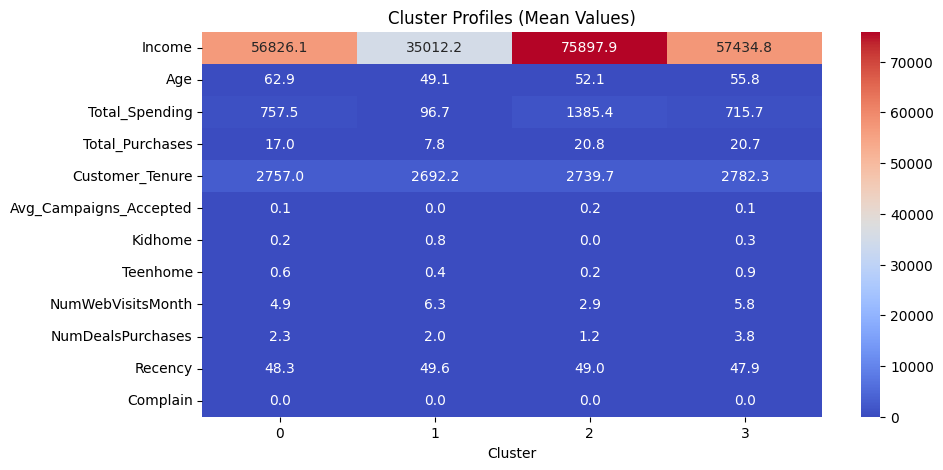

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

profile_summary = df.groupby('Cluster')[profile_cols].mean()

plt.figure(figsize=(10, 5))
sns.heatmap(profile_summary.T, annot=True, fmt='.1f', cmap='coolwarm')
plt.title('Cluster Profiles (Mean Values)')
plt.show()

In [ ]:
# Cluster size counts
cluster_sizes = df['Cluster'].value_counts().sort_index()

# Map cluster numbers to persona names
cluster_names = {
    0: "Older, Moderate-Income Steady Spenders",
    1: "Low-Income, Low-Engagement Families",
    2: "High-Income Premium Buyers (VIPs)",
    3: "Mid-Income, Deal-Driven Families"
}

# Business recommendation per cluster
cluster_actions = {
    0: "Focus on retention & loyalty messaging (stable, less price-sensitive, older audience).",
    1: "Re-engagement campaigns, entry-level bundles, first-purchase incentives (high browsing, low conversion).",
    2: "Premium offers, early access, loyalty rewards (biggest spenders, most campaign-responsive).",
    3: "Discount/coupon campaigns (frequent buyers, price-sensitive, respond well to deals)."
}

# Print formatted summary
print("="*80)
print("CUSTOMER SEGMENTATION — CLUSTER PROFILES SUMMARY")
print("="*80)

for cluster_id in sorted(df['Cluster'].unique()):
    size = cluster_sizes[cluster_id]
    pct = (size / len(df)) * 100
    income = df[df['Cluster'] == cluster_id]['Income'].mean()
    spending = df[df['Cluster'] == cluster_id]['Total_Spending'].mean()
    age = df[df['Cluster'] == cluster_id]['Age'].mean()
    purchases = df[df['Cluster'] == cluster_id]['Total_Purchases'].mean()

    print(f"\nCluster {cluster_id}: {cluster_names[cluster_id]}")
    print(f"  Size: {size} customers ({pct:.1f}%)")
    print(f"  Avg Income: {income:,.0f} | Avg Spending: {spending:,.0f} | "
          f"Avg Age: {age:.1f} | Avg Purchases: {purchases:.1f}")
    print(f"  Recommended Action: {cluster_actions[cluster_id]}")

print("\n" + "="*80)

CUSTOMER SEGMENTATION — CLUSTER PROFILES SUMMARY

Cluster 0: Older, Moderate-Income Steady Spenders
  Size: 71 customers (3.4%)
  Avg Income: 56,826 | Avg Spending: 757 | Avg Age: 62.9 | Avg Purchases: 17.0
  Recommended Action: Focus on retention & loyalty messaging (stable, less price-sensitive, older audience).

Cluster 1: Low-Income, Low-Engagement Families
  Size: 926 customers (45.0%)
  Avg Income: 35,012 | Avg Spending: 97 | Avg Age: 49.1 | Avg Purchases: 7.8
  Recommended Action: Re-engagement campaigns, entry-level bundles, first-purchase incentives (high browsing, low conversion).

Cluster 2: High-Income Premium Buyers (VIPs)
  Size: 504 customers (24.5%)
  Avg Income: 75,898 | Avg Spending: 1,385 | Avg Age: 52.1 | Avg Purchases: 20.8
  Recommended Action: Premium offers, early access, loyalty rewards (biggest spenders, most campaign-responsive).

Cluster 3: Mid-Income, Deal-Driven Families
  Size: 557 customers (27.1%)
  Avg Income: 57,435 | Avg Spending: 716 | Avg Age: 55.8

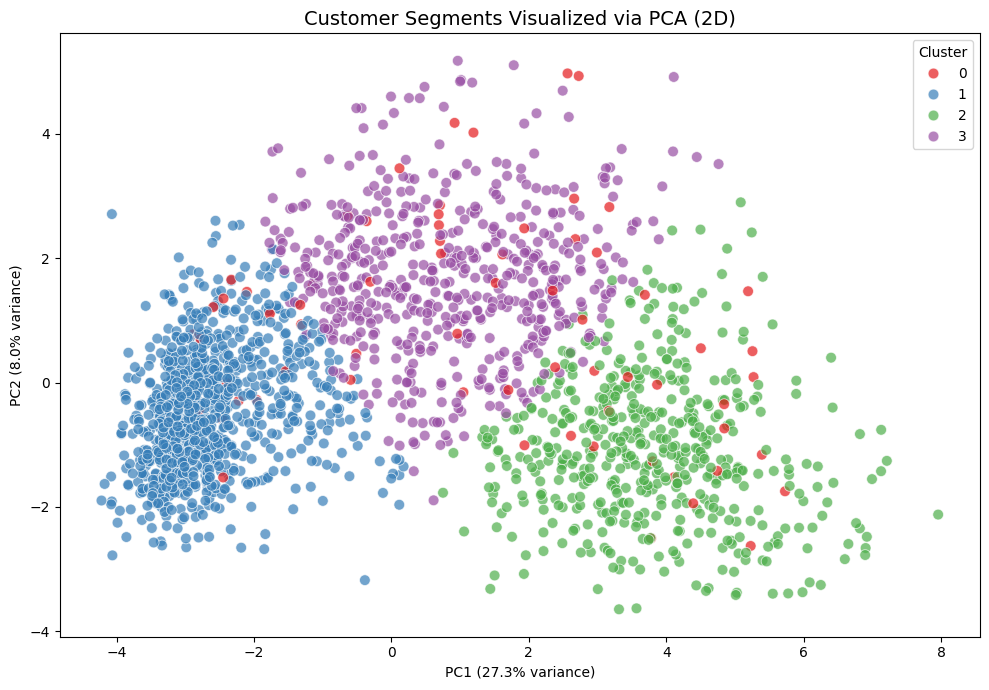

In [ ]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns

# Reduce scaled features to 2D for visualization
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

# Put into a DataFrame for easy plotting
pca_df = pd.DataFrame(X_pca, columns=['PC1', 'PC2'])
pca_df['Cluster'] = df['Cluster'].values

# Plot
plt.figure(figsize=(10, 7))
sns.scatterplot(data=pca_df, x='PC1', y='PC2', hue='Cluster',
                 palette='Set1', s=60, alpha=0.7)

plt.title('Customer Segments Visualized via PCA (2D)', fontsize=14)
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)')
plt.legend(title='Cluster')
plt.tight_layout()
plt.show()